| Keputusan | Alasan |
|---|---|
| Memakai `SelfTrainingClassifier` | Alur semi-supervised mudah dijelaskan: latih model pada data berlabel, beri pseudo-label pada contoh yang sangat diyakini, lalu latih ulang. |
| Memakai Logistic Regression sebagai baseline | Model dasar relatif sederhana, cepat untuk banyak fitur numerik, dan menyediakan probabilitas yang dibutuhkan oleh self-training. Model ini menjadi baseline, bukan klaim bahwa ia model terbaik. |
| menggunakan rasio 75% untuk training set dan 25% untuk test set | Rasio 75:25 dipilih sebagai kompromi praktis berdasarkan ukuran dataset dan kebutuhan evaluasi, bukan sebagai rasio optimal yang berlaku universal. |
| 20% training set label dan 80% training set non-label | Mensimulasikan situasi label mahal atau terbatas. |
| Menentukan jumlah fitur dengan cross-validation | kandidat diuji pada fold training berlabel dan dipilih berdasarkan F1 kelas DDoS. |
| Memilih fitur dengan Mutual Information | Skor mengukur seberapa banyak informasi sebuah fitur tentang kelas. Skor dipelajari hanya dari label training yang tersedia. |
| Ambang pseudo-label 0,80 | Hanya prediksi dengan probabilitas maksimum minimal 80% yang ditambahkan, untuk mengurangi pseudo-label yang terlalu meragukan. Ambang ini adalah titik awal yang perlu diuji, bukan angka universal. |
| Median imputation dan StandardScaler | Nilai tak hingga diubah menjadi missing; median menangani missing values, sedangkan scaling menyamakan skala fitur untuk Logistic Regression. |
| Membandingkan dengan supervised baseline | Menilai apakah pemanfaatan data tanpa label benar-benar membantu dibanding memakai label yang sama saja. |

**Catatan penting:** CSV ini memiliki label asli. Untuk membuat eksperimen semi-supervised, label pada sebagian data training sengaja disembunyikan. Label tersembunyi tersebut tidak diberikan kepada model. Test set tetap berlabel hanya untuk evaluasi. Ini simulasi semi-supervised, bukan dataset yang sejak awal benar-benar tidak berlabel.

# 1. Import Library

In [549]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)

# 2. Exploratory Data Analysis (EDA)

In [550]:
df = pd.read_csv('Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv')

In [551]:
df.sample(5)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
206313,53,47126,4,2,132,210,33,33,33.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
152298,80,904082,3,6,26,11607,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
64073,80,151518,3,5,26,11607,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS
18189,443,94782,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
23315,80,1823340,3,4,26,11601,20,0,8.666667,10.263203,...,20,0.0,0.0,0,0,0.0,0.0,0,0,DDoS


In [552]:
print("Jumlah baris: ", df.shape[0])
print("Jumlah kolom: ", df.shape[1])

Jumlah baris:  225745
Jumlah kolom:  79


In [553]:
print("nama kolom: ", df.columns.tolist())

nama kolom:  [' Destination Port', ' Flow Duration', ' Total Fwd Packets', ' Total Backward Packets', 'Total Length of Fwd Packets', ' Total Length of Bwd Packets', ' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', ' Fwd Packet Length Std', 'Bwd Packet Length Max', ' Bwd Packet Length Min', ' Bwd Packet Length Mean', ' Bwd Packet Length Std', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Std', ' Flow IAT Max', ' Flow IAT Min', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', ' Fwd IAT Min', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Std', ' Bwd IAT Max', ' Bwd IAT Min', 'Fwd PSH Flags', ' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' Fwd Header Length', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', 'FIN Flag Count', ' SYN Flag Count', ' RST Flag Count', ' PSH Flag Count', ' ACK Flag Count'

In [554]:
# Membersihkan spasi di awal/akhir nama kolom
df.columns = df.columns.str.strip()

In [555]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Destination Port             225745 non-null  int64  
 1   Flow Duration                225745 non-null  int64  
 2   Total Fwd Packets            225745 non-null  int64  
 3   Total Backward Packets       225745 non-null  int64  
 4   Total Length of Fwd Packets  225745 non-null  int64  
 5   Total Length of Bwd Packets  225745 non-null  int64  
 6   Fwd Packet Length Max        225745 non-null  int64  
 7   Fwd Packet Length Min        225745 non-null  int64  
 8   Fwd Packet Length Mean       225745 non-null  float64
 9   Fwd Packet Length Std        225745 non-null  float64
 10  Bwd Packet Length Max        225745 non-null  int64  
 11  Bwd Packet Length Min        225745 non-null  int64  
 12  Bwd Packet Length Mean       225745 non-null  float64
 13 

In [556]:
df.describe()

c:\Users\Mirwan Qolyubi\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\Mirwan Qolyubi\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,225745.00000,2.257450e+05,225745.000000,225745.000000,225745.000000,2.257450e+05,225745.000000,225745.000000,225745.000000,225745.000000,...,225745.000000,225745.000000,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05
mean,8879.61946,1.624165e+07,4.874916,4.572775,939.463346,5.960477e+03,538.535693,27.882221,164.826715,214.907242,...,3.311497,21.482753,1.848261e+05,1.293436e+04,2.080849e+05,1.776201e+05,1.032214e+07,3.611943e+06,1.287813e+07,7.755355e+06
std,19754.64740,3.152437e+07,15.422874,21.755356,3249.403484,3.921834e+04,1864.128991,163.324159,504.892965,797.411073,...,12.270018,4.166799,7.979250e+05,2.102737e+05,9.002350e+05,7.842602e+05,2.185303e+07,1.275689e+07,2.692126e+07,1.983109e+07
min,0.00000,-1.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,80.00000,7.118000e+04,2.000000,1.000000,26.000000,0.000000e+00,6.000000,0.000000,6.000000,0.000000,...,1.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,80.00000,1.452333e+06,3.000000,4.000000,30.000000,1.640000e+02,20.000000,0.000000,8.666667,5.301991,...,2.000000,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,80.00000,8.805237e+06,5.000000,5.000000,63.000000,1.160100e+04,34.000000,6.000000,32.000000,10.263203,...,4.000000,20.000000,1.878000e+03,0.000000e+00,1.878000e+03,1.862000e+03,8.239725e+06,0.000000e+00,8.253838e+06,7.422849e+06
max,65532.00000,1.199999e+08,1932.000000,2942.000000,183012.000000,5.172346e+06,11680.000000,1472.000000,3867.000000,6692.644993,...,1931.000000,52.000000,1.000000e+08,3.950000e+07,1.000000e+08,1.000000e+08,1.200000e+08,6.530000e+07,1.200000e+08,1.200000e+08


In [557]:
df['Label'].value_counts()

Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

C:\Users\Mirwan Qolyubi\AppData\Local\Temp\ipykernel_12036\2292890557.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Label', palette='viridis')


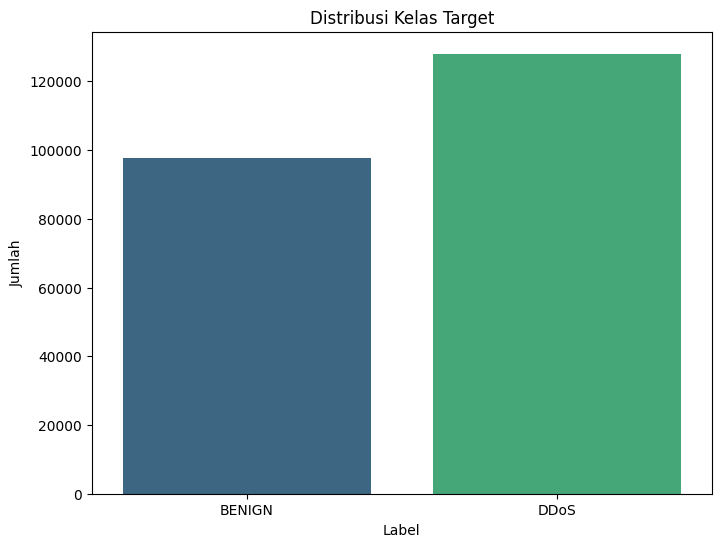

In [558]:
# Visualisasi distribusi kolom target 'Label'
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='Label', palette='viridis')
plt.title('Distribusi Kelas Target')
plt.ylabel('Jumlah')
plt.show()

In [559]:
print("Data duplikat: ", df.duplicated().sum())

Data duplikat:  2633


In [560]:
print("Data missing: ", df.isnull().sum().sum())

Data missing:  4


In [561]:
df.nunique()

Destination Port                23950
Flow Duration                  187752
Total Fwd Packets                 297
Total Backward Packets            367
Total Length of Fwd Packets      3831
Total Length of Bwd Packets      6760
Fwd Packet Length Max            1891
Fwd Packet Length Min             151
Fwd Packet Length Mean           7401
Fwd Packet Length Std            9555
Bwd Packet Length Max            1945
Bwd Packet Length Min             343
Bwd Packet Length Mean           8655
Bwd Packet Length Std            9650
Flow Bytes/s                   202293
Flow Packets/s                 194094
Flow IAT Mean                  193666
Flow IAT Std                   159622
Flow IAT Max                   139745
Flow IAT Min                    11093
Fwd IAT Total                   78049
Fwd IAT Mean                    95095
Fwd IAT Std                     91184
Fwd IAT Max                     77978
Fwd IAT Min                      8820
Bwd IAT Total                  101942
Bwd IAT Mean

In [562]:
# Mengecek apakah ada nilai tak hingga (infinity) dalam DataFrame
np.isinf(df.select_dtypes(include=np.number)).sum()

Destination Port                0
Flow Duration                   0
Total Fwd Packets               0
Total Backward Packets          0
Total Length of Fwd Packets     0
Total Length of Bwd Packets     0
Fwd Packet Length Max           0
Fwd Packet Length Min           0
Fwd Packet Length Mean          0
Fwd Packet Length Std           0
Bwd Packet Length Max           0
Bwd Packet Length Min           0
Bwd Packet Length Mean          0
Bwd Packet Length Std           0
Flow Bytes/s                   30
Flow Packets/s                 34
Flow IAT Mean                   0
Flow IAT Std                    0
Flow IAT Max                    0
Flow IAT Min                    0
Fwd IAT Total                   0
Fwd IAT Mean                    0
Fwd IAT Std                     0
Fwd IAT Max                     0
Fwd IAT Min                     0
Bwd IAT Total                   0
Bwd IAT Mean                    0
Bwd IAT Std                     0
Bwd IAT Max                     0
Bwd IAT Min   

# 3. Data Preprocessing & Feature Engineering

## 3.1 Data Cleaning

In [563]:
# Menghapus baris duplikat
df = df.drop_duplicates()
print("Data duplikat setelah penghapusan: ", df.duplicated().sum())

Data duplikat setelah penghapusan:  0


In [564]:
# Mengganti nilai tak hingga (infinity) dengan NaN
kolom_numerik = df.select_dtypes(include=[np.number]).columns
df[kolom_numerik] = df[kolom_numerik].replace([np.inf, -np.inf], np.nan)
print("Jumlah nilai NaN setelah penggantian: ", df.isnull().sum().sum())

Jumlah nilai NaN setelah penggantian:  60


In [565]:
# Inputasi nilai NaN dengan median kolom
df[kolom_numerik] = df[kolom_numerik].fillna(df[kolom_numerik].median())
print("Jumlah nilai NaN setelah inputasi: ", df.isnull().sum().sum())

Jumlah nilai NaN setelah inputasi:  0


## 3.2 Split Data

In [566]:
# Memisahkan fitur dan target
X = df.drop(columns=['Label'])
y = df['Label'].map({'BENIGN': 0, 'DDoS': 1})  # Mengubah label menjadi biner

In [567]:
# Memisahkan data menjadi train(75%) dan test(25%) dengan stratifikasi agar proporsi kelas tetap terjaga
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)
print(f"Data training: {len(X_train):,} baris")
print(f"Data test:     {len(X_test):,} baris")

Data training: 167,334 baris
Data test:     55,778 baris


In [568]:
# Memisahkan data training menjadi data berlabel (20%) dan data tanpa label (80%) dengan stratifikasi agar proporsi kelas tetap terjaga
X_labeled, X_unlabeled, y_labeled, _ = train_test_split(
    X_train, y_train, train_size=0.20,
    stratify=y_train, random_state=42
)
print(f"Training berlabel:   {len(X_labeled):,} baris")
print(f"Training tanpa label: {len(X_unlabeled):,} baris")

Training berlabel:   33,466 baris
Training tanpa label: 133,868 baris


## 3.3 Feature Selection

In [569]:
# Menentukan kandidat jumlah fitur (K) untuk pemilihan fitur
K_CANDIDATES = sorted(
    set(k for k in [5, 10, 15, 20, 30, 40, 60, X_labeled.shape[1]]
        if k <= X_labeled.shape[1])
)

cv_fs = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print("Kandidat jumlah fitur:", K_CANDIDATES)
print("Jumlah fold:", cv_fs.get_n_splits())

Kandidat jumlah fitur: [5, 10, 15, 20, 30, 40, 60, 78]
Jumlah fold: 3


In [570]:
# Mengevaluasi model dengan cross-validation untuk setiap kandidat jumlah fitur
rekap_cv = []

for nomor_fold, (idx_train, idx_valid) in enumerate(
    cv_fs.split(X_labeled, y_labeled), start=1
):
    X_fold_train = X_labeled.iloc[idx_train]
    X_fold_valid = X_labeled.iloc[idx_valid]
    y_fold_train = y_labeled.iloc[idx_train]
    y_fold_valid = y_labeled.iloc[idx_valid]

    # Imputasi hanya dipelajari dari bagian training fold.
    imputer_fold = SimpleImputer(
        strategy="median",
        keep_empty_features=True
    )
    Xtr = imputer_fold.fit_transform(X_fold_train)
    Xval = imputer_fold.transform(X_fold_valid)

    # Peringkat fitur hanya dihitung dari training fold berlabel.
    skor_mi = mutual_info_classif(
        Xtr, y_fold_train,
        random_state=42
    )
    urutan_fitur = np.argsort(skor_mi)[::-1]

    for k in K_CANDIDATES:
        indeks_pilihan = urutan_fitur[:k]

        scaler_fold = StandardScaler()
        Xtr_scaled = scaler_fold.fit_transform(Xtr[:, indeks_pilihan])
        Xval_scaled = scaler_fold.transform(Xval[:, indeks_pilihan])

        model_fold = LogisticRegression(max_iter=500, random_state=42)
        model_fold.fit(Xtr_scaled, y_fold_train)
        pred_valid = model_fold.predict(Xval_scaled)

        rekap_cv.append({
            "Fold": nomor_fold,
            "Jumlah fitur": k,
            "F1 DDoS": f1_score(
                y_fold_valid, pred_valid,
                pos_label=1, zero_division=0
            )
        })

hasil_cv_detail = pd.DataFrame(rekap_cv)
ringkasan_cv = (
    hasil_cv_detail.groupby("Jumlah fitur")["F1 DDoS"]
    .agg(Rata_rata_F1="mean", Simpangan_baku="std")
    .reset_index()
)

display(ringkasan_cv.round(5))

,Jumlah fitur,Rata_rata_F1,Simpangan_baku
0,5,0.76643,0.00281
1,10,0.97724,0.00143
2,15,0.98156,0.00062
3,20,0.98811,0.00137
4,30,0.99618,0.00020
5,40,0.99618,0.00062
6,60,0.99409,0.00051
7,78,0.99487,0.00069


In [571]:
# Menentukan jumlah fitur terpilih berdasarkan aturan one-standard-error
baris_terbaik = ringkasan_cv.loc[ringkasan_cv["Rata_rata_F1"].idxmax()]
f1_terbaik = float(baris_terbaik["Rata_rata_F1"])
se_terbaik = float(baris_terbaik["Simpangan_baku"]) / np.sqrt(
    cv_fs.get_n_splits()
)
ambang_one_se = f1_terbaik - se_terbaik

kandidat_memadai = ringkasan_cv[
    ringkasan_cv["Rata_rata_F1"] >= ambang_one_se
]
jumlah_fitur_terpilih = int(kandidat_memadai["Jumlah fitur"].min())

print(f"F1 CV terbaik: {f1_terbaik:.5f}")
print(f"Standard error kandidat terbaik: {se_terbaik:.5f}")
print(f"Ambang one-standard-error: {ambang_one_se:.5f}")
print(f"Jumlah fitur terpilih: {jumlah_fitur_terpilih} dari {X_labeled.shape[1]}")

F1 CV terbaik: 0.99618
Standard error kandidat terbaik: 0.00012
Ambang one-standard-error: 0.99607
Jumlah fitur terpilih: 30 dari 78


In [572]:
# Pelajari peringkat fitur dari subset training berlabel saja.
selector_fs = SelectKBest(
    score_func=lambda X_input, y_input: mutual_info_classif(
        X_input, y_input, random_state=42
    ),
    k=jumlah_fitur_terpilih
)
selector_fs.fit(X_labeled, y_labeled)

fitur_terpilih = X_labeled.columns[
    selector_fs.get_support()
].tolist()

# Terapkan daftar fitur yang sama ke semua bagian data.
X_labeled_fs = X_labeled[fitur_terpilih].copy()
X_unlabeled_fs = X_unlabeled[fitur_terpilih].copy()
X_test_fs = X_test[fitur_terpilih].copy()

print(f"Fitur awal: {X_labeled.shape[1]}")
print(f"Fitur terpilih: {len(fitur_terpilih)}")
print(f"Pengurangan fitur: {100 * (1 - len(fitur_terpilih) / X_labeled.shape[1]):.1f}%")

Fitur awal: 78
Fitur terpilih: 30
Pengurangan fitur: 61.5%


In [573]:
# Tabel skor mutual information untuk semua fitur
skor_mi_final = selector_fs.scores_
tabel_fitur = pd.DataFrame({
    "Fitur": X_labeled.columns,
    "Skor Mutual Information": skor_mi_final,
    "Terpilih": selector_fs.get_support()
}).sort_values("Skor Mutual Information", ascending=False)

display(tabel_fitur.head(35).round(5))

,Fitur,Skor Mutual Information,Terpilih
4,Total Length of Fwd Packets,0.64961,True
63,Subflow Fwd Bytes,0.64879,True
52,Average Packet Size,0.55324,True
54,Avg Bwd Segment Size,0.54750,True
65,Subflow Bwd Bytes,0.54680,True
5,Total Length of Bwd Packets,0.54650,True
12,Bwd Packet Length Mean,0.54552,True
0,Destination Port,0.54211,True
55,Fwd Header Length.1,0.53855,True
34,Fwd Header Length,0.53832,True


# 4. Machine Learning

## 4.1 Baseline (logistik regresion)

In [ ]:
def buat_model_dasar():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("logistic_regression", LogisticRegression(max_iter=500, random_state=42))
    ])

In [ ]:
model_supervised = buat_model_dasar()
model_supervised.fit(X_labeled_fs, y_labeled)
print("Baseline selesai dilatih.")

In [ ]:
y_pred_supervised = model_supervised.predict(X_test_fs)
print("Prediksi baseline selesai.")

## 4.2 Self Training

In [ ]:
X_semi = pd.concat(
    [X_labeled_fs, X_unlabeled_fs],
    axis=0,
    ignore_index=True
)

print("Jumlah sampel untuk Self-Training:", f"{len(X_semi):,}")

In [ ]:
y_semi = np.concatenate([
    y_labeled.to_numpy(),
    np.full(len(X_unlabeled_fs), -1, dtype=int)
])

print("Sampel berlabel:", int((y_semi != -1).sum()))
print("Sampel tanpa label:", int((y_semi == -1).sum()))

## 4.2 Melatih Model Self Training

In [ ]:
model_semi = SelfTrainingClassifier(
    estimator=buat_model_dasar(),
    criterion="threshold",
    threshold=0.80,
    max_iter=5,
    verbose=True
)

model_semi.fit(X_semi, y_semi)
print("Self-Training selesai.")

In [ ]:
iterasi_label = model_semi.labeled_iter_
status_unlabeled = iterasi_label[len(X_labeled_fs):]

jumlah_pseudo = int((status_unlabeled > 0).sum())
jumlah_tanpa_label = int((status_unlabeled == -1).sum())

print("Pseudo-label yang ditambahkan:", f"{jumlah_pseudo:,}")
print("Masih tanpa label:", f"{jumlah_tanpa_label:,}")

In [ ]:
mask_pseudo = status_unlabeled > 0
pseudo_pred = model_semi.transduction_[len(X_labeled_fs):][mask_pseudo]

if mask_pseudo.sum() > 0:
    posisi_pseudo = np.flatnonzero(mask_pseudo)
    label_asli_audit = y_unlabeled_audit.iloc[posisi_pseudo].to_numpy()
    akurasi_pseudo = accuracy_score(label_asli_audit, pseudo_pred)
    print(f"Akurasi pseudo-label pada sampel terpilih: {akurasi_pseudo:.2%}")
else:
    print("Tidak ada pseudo-label; audit akurasi tidak dapat dihitung.")